# Lead-aligned coronal-hole features

**The question:** should the coronal-hole input be timed against each forecast hour rather than
against t0?

**Now:** the linear model uses the central-meridian strip of one image, 24 h before t0
(`ch_cm_at_24h`), for every lead. For lead k that is an image taken 25 + k hours before the hour
being forecast: 26 h for lead 1, 97 h for lead 72.

**Lead-aligned at delay D:** lead k uses the strip of the image about D hours before t0 + k, i.e. at
lag L_k = D − k before t0, rounded up to the 6-hour image grid (at least 0). Collin et al. (2025)
time their coronal-hole features against the target this way.

**No model change is needed for the test** (`training.lead_aligned_ch.Stitched`): the linear model
fits each lead on its own, so a model whose lead k uses the column at L_k equals one fitted with
that column, lead by lead. Each distinct L_k gets its own LinearModel (13 per variant).

**Variants** on the shipped config (data fixes and regressor cap included):
- `at D`: `ch_cm_at_24h` replaced by the lead-aligned strip, D = 60 … 120 h;
- `+ at D`: the lead-aligned strip added to `ch_cm_at_24h`;
- (24-hour window means of the strip were worse on the 2024 pilot fold, +1% to +6%, and were left out.)

The hybrid's trees were refitted on the three best linear variants.

**Setup:** six yearly walk-forward folds (2019-10 → 2025-10), fitted on the data before each fold.
Score: per-run mean TIMSE / persistence, as a geometric mean over folds. The eval year is not used.

1. Score against delay
2. Fold scores
3. The hybrid
4. What the alignment changes (2024 fold)
5. Findings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import lead_aligned_ch as la

df = pd.read_csv(la.EXPERIMENTS / "lead_aligned_ch.csv").set_index("fold")


def geo(c):
    return float(np.exp(np.log(df[c]).mean()))


def rel(c, ref):
    return geo(c) / geo(ref) - 1

## 1. Score against delay (linear model)

,at D,at D vs shipped,at D folds won,+ at D,+ at D vs shipped,+ at D folds won
delay D (h),,,,,,
60,0.4335,-0.0092,4,0.4298,-0.0177,5
66,0.4287,-0.0202,5,0.4281,-0.0216,4
72,0.4257,-0.0271,5,0.4271,-0.0238,4
78,0.4269,-0.0244,5,0.4279,-0.0220,5
84,0.4334,-0.0094,3,0.4310,-0.0151,3
90,0.4422,0.0106,2,0.4339,-0.0083,3
96,0.4512,0.0311,0,0.4354,-0.0048,3
102,0.4591,0.0492,0,0.4363,-0.0028,3
108,0.4646,0.0619,0,0.4367,-0.0019,4


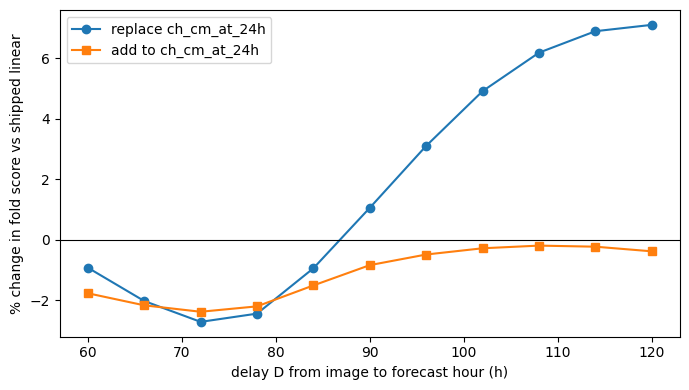

In [2]:
rows = []
for d in la.DELAYS:
    rows.append({"delay D (h)": d,
                 "at D": geo(f"linear at {d}"),
                 "at D vs shipped": rel(f"linear at {d}", "linear shipped"),
                 "at D folds won": int((df[f"linear at {d}"] < df["linear shipped"]).sum()),
                 "+ at D": geo(f"linear + at {d}"),
                 "+ at D vs shipped": rel(f"linear + at {d}", "linear shipped"),
                 "+ at D folds won": int((df[f"linear + at {d}"] < df["linear shipped"]).sum())})
curve = pd.DataFrame(rows).set_index("delay D (h)")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(curve)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve.index, 100 * curve["at D vs shipped"], "o-", label="replace ch_cm_at_24h")
ax.plot(curve.index, 100 * curve["+ at D vs shipped"], "s-", label="add to ch_cm_at_24h")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("delay D from image to forecast hour (h)")
ax.set_ylabel("% change in fold score vs shipped linear")
ax.legend()
plt.tight_layout()

## 2. Fold scores

In [3]:
cols = ["linear shipped", "linear at 72", "linear at 78", "linear + at 72",
        "hybrid shipped", "hybrid at 72", "hybrid at 78", "hybrid + at 72"]
display(df[cols].T.round(4))

fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
linear shipped,0.4282,0.3678,0.4981,0.4626,0.5554,0.3481
linear at 72,0.3978,0.3502,0.4995,0.4538,0.5429,0.3471
linear at 78,0.3947,0.3496,0.5017,0.4600,0.5533,0.3434
linear + at 72,0.3981,0.3518,0.5015,0.4572,0.5406,0.3499
hybrid shipped,0.3960,0.3604,0.4900,0.4573,0.5488,0.3371
hybrid at 72,0.3789,0.3520,0.4853,0.4461,0.5363,0.3448
hybrid at 78,0.3776,0.3530,0.4929,0.4579,0.5494,0.3390
hybrid + at 72,0.3835,0.3539,0.4877,0.4518,0.5352,0.3437


## 3. The hybrid (trees refitted on each linear variant)

In [4]:
hyb = pd.DataFrame({c: {"score": geo(c), "vs shipped hybrid": rel(c, "hybrid shipped"),
                        "folds won": int((df[c] < df["hybrid shipped"]).sum())}
                    for c in ("hybrid shipped", "hybrid at 72", "hybrid at 78",
                              "hybrid + at 72")}).T
with pd.option_context("display.float_format", "{:.4f}".format):
    display(hyb)

,score,vs shipped hybrid,folds won
hybrid shipped,0.4253,0.0000,0.0000
hybrid at 72,0.4181,-0.0170,5.0000
hybrid at 78,0.4214,-0.0091,2.0000
hybrid + at 72,0.4202,-0.0121,5.0000


## 4. What the alignment changes (2024 fold)

The coefficient of the standardised strip, by lead: shipped (one image, 24 h before t0) against
lead-aligned at D = 72 h (lead k from the image at lag 72 − k, rounded up to 6 h).

,shipped,lead-aligned D=72,lag (h)
1,-0.2,1.4,72
6,3.1,7.2,66
12,7.0,14.2,60
24,19.5,23.7,48
36,28.8,30.9,36
48,29.7,29.7,24
60,26.2,28.6,12
72,13.7,23.5,0


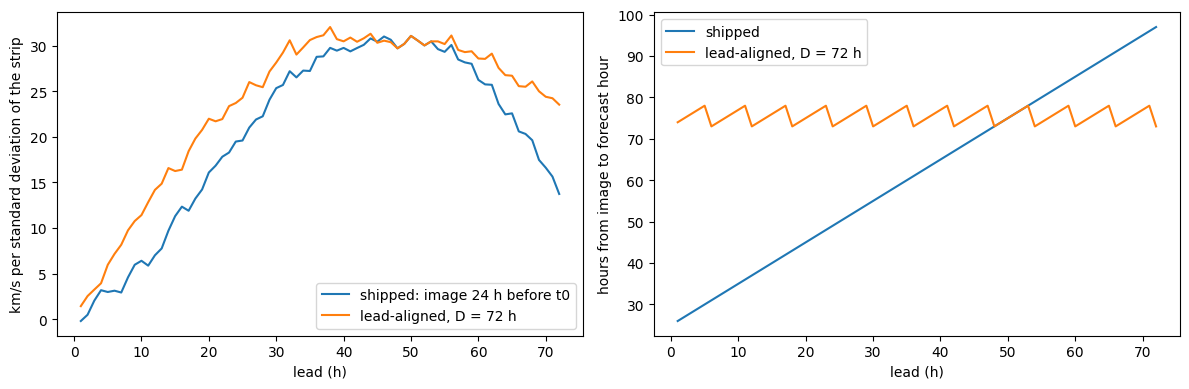

In [5]:
from models.linear_model import LinearModel
from training import compare_history as ch
from training.datasets import DATA_START

data = ch.Data()
table = la.load_table(data)
start, end = la.YEARLY[-1]
start_pos = data.series.index.get_loc(start)
fit6 = data.runs6[(data.runs6 >= DATA_START) & (data.runs6 < start)]
pos6 = data.series.index.get_indexer(fit6)


def x(t0s, names):
    return table.loc[t0s, list(names)].to_numpy(dtype=float)


shipped = LinearModel(data.linear_cfg).fit(data.values, pos6, x(fit6, data.linear_cfg.features),
                                           end=start_pos)
feats, lags, _ = la.variants(data.linear_cfg.features)["at 72"]
st = la.Stitched(data.linear_cfg, feats, lags)
st.fit(data.values, pos6, x(fit6, st.config.features), end=start_pos)
col = 1 + data.linear_cfg.n_speed
i_ship = col + data.linear_cfg.features.index(la.FIXED)
coef_ship = shipped.coef[:, i_ship]
coef_al = np.array([st.models[int(lag)].coef[k, col + len(feats)] for k, lag in enumerate(lags)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
leads = np.arange(1, 73)
axes[0].plot(leads, coef_ship, label="shipped: image 24 h before t0")
axes[0].plot(leads, coef_al, label="lead-aligned, D = 72 h")
axes[0].set_xlabel("lead (h)")
axes[0].set_ylabel("km/s per standard deviation of the strip")
axes[0].legend()
axes[1].plot(leads, 25 + leads, label="shipped")
axes[1].plot(leads, leads + lags + 1, label="lead-aligned, D = 72 h")
axes[1].set_xlabel("lead (h)")
axes[1].set_ylabel("hours from image to forecast hour")
axes[1].legend()
plt.tight_layout()
display(pd.DataFrame({"shipped": coef_ship, "lead-aligned D=72": coef_al,
                     "lag (h)": lags}, index=leads).loc[[1, 6, 12, 24, 36, 48, 60, 72]].round(1))

## 5. Findings

- **Lead-aligned coronal holes help.** At D = 72 h the linear model gains 2.7% (0.4375 → 0.4257, 5 of 6 folds) and the hybrid refitted on it 1.7% (0.4253 → 0.4181, 5 of 6 folds). The hybrid loses the 2024 fold (+2.3%); the linear model is level there (−0.3%).
- **The delay curve is smooth,** with its best at 72–78 h: −0.9% at 60 h, −2.0% at 66 h, −2.7% at 72 h, −2.4% at 78 h, then worse as D grows (+3.1% at 96 h, +7.1% at 120 h). D was chosen among 11 values on the same folds, which flatters the winner a little; the smooth curve and 5 of 6 folds make it unlikely to be noise.
- **72 h is shorter than the 4–5 days expected from slow-wind travel times.** The strip's effect is largest on fast streams (fast wind takes about 2.5–3 days), and the rounding to the 6-hour image grid plus the 1-hour image latency put the actual delay at 73–78 h. Collin et al.'s 4–7 days are measured to the target day at Earth from OMNI daily means, a coarser timing.
- **Where the gain comes from:** the two models agree at lead 48, where both use the image 24 h before t0. At the far leads the shipped image is 85–97 h older than the forecast hour; the aligned one is 72–78 h older, and its coefficient stays high (23.5 against 13.7 km/s per standard deviation at lead 72). At the short leads both are small, as the last observed speed dominates.
- **Replacing beats adding:** keeping `ch_cm_at_24h` next to the aligned strip is slightly worse (−2.4% linear, −1.2% hybrid).
- **The 24-hour window mean** (images D … D + 24 h before each hour) was worse on the pilot fold, so the single image is enough.
- **Decision:** worth building into the shipped linear model (the hybrid's anchor). It needs per-lead regressors in `LinearModel` and 13 images at lags 0–72 h live instead of 4 (each 512-pixel browse image is small).